# Task 1: Big Data Analysis with Dask
**EliteTech Intern – Data Analytics Internship**

**Objective:** Analyse a large dataset with **Dask** and show that the approach scales.

**Dataset:** [Our World in Data – COVID-19 dataset](https://github.com/owid/covid-19-data). It has about **429,000 rows × 67 columns** (~100 MB CSV) of daily records for every country from 2020 onward: cases, deaths, tests, vaccinations, and demographic indicators.

**Why Dask?** Dask splits a large table into many smaller **partitions** and processes them in parallel, lazily (nothing runs until `.compute()` is called). The same code runs on a laptop, on a multi-core server, or on a cluster, and can handle data that is larger than RAM.

**Contents**
1. Setup and data loading (partitioned read)
2. Data understanding and cleaning
3. Big-data aggregations and insights
4. Scalability demonstration (CSV vs Parquet, data-size scaling, parallelism)
5. Summary of insights

## 1. Setup and data loading

In [1]:
# Import the libraries we need
import os
import time
import urllib.request

import dask
import dask.dataframe as dd
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True
print("Dask version:", dask.__version__)
print("CPU cores available:", os.cpu_count())

Dask version: 2026.8.0
CPU cores available: 2


In [2]:
# Location of the dataset. It is ~100 MB, so it is NOT stored in the GitHub repo;
# we download it automatically the first time the notebook runs.
DATA_DIR = "../data"
CSV_PATH = os.path.join(DATA_DIR, "owid-covid-data.csv")
URL = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"

os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(CSV_PATH):
    print("Downloading dataset (~100 MB)...")
    urllib.request.urlretrieve(URL, CSV_PATH)
print(f"File size: {os.path.getsize(CSV_PATH) / 1e6:.1f} MB")

File size: 98.4 MB


In [3]:
# Read the CSV with Dask.
# blocksize="16MB" tells Dask to split the file into ~16 MB chunks (partitions)
# that can be processed in parallel. Text columns are declared explicitly;
# assume_missing=True makes all other numeric columns float (they contain blanks).
text_cols = {"iso_code": "object", "continent": "object", "location": "object",
             "date": "object", "tests_units": "object"}

ddf = dd.read_csv(CSV_PATH, blocksize="16MB", dtype=text_cols, assume_missing=True)

print("Number of partitions:", ddf.npartitions)
print("Number of columns   :", len(ddf.columns))
# Note: nothing has been loaded into memory yet. Dask has only built a task graph.

Number of partitions: 6
Number of columns   : 67


In [4]:
# Count rows. This triggers real (parallel) computation across all partitions.
start = time.perf_counter()
n_rows = len(ddf)
print(f"Total rows: {n_rows:,}  (counted in {time.perf_counter() - start:.2f} s)")

Total rows: 429,435  (counted in 0.92 s)


In [5]:
# Peek at the first few rows (only the first partition is read)
ddf.head()

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772.0,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772.0,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772.0,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772.0,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772.0,NaN,NaN,NaN,NaN


## 2. Data understanding and cleaning

The OWID file mixes **real countries** with **aggregate rows** (such as "World", "Asia" or "High-income countries") and a few sub-national or special rows (England, Scotland, Kosovo and others). All of them have ISO codes starting with `OWID_`. We keep only real countries so totals are not double-counted.

In [6]:
# Look at what aggregate rows exist
aggregates = ddf[ddf["iso_code"].str.startswith("OWID_")]["location"].unique().compute()
print("Aggregate rows (removed from country analysis):")
print(sorted(aggregates.tolist()))

Aggregate rows (removed from country analysis):
['Africa', 'Asia', 'England', 'Europe', 'European Union (27)', 'High-income countries', 'Kosovo', 'Low-income countries', 'Lower-middle-income countries', 'North America', 'Northern Cyprus', 'Northern Ireland', 'Oceania', 'Scotland', 'South America', 'Upper-middle-income countries', 'Wales', 'World']


In [7]:
# Keep only real countries and parse the date column.
countries = ddf[~ddf["iso_code"].str.startswith("OWID_")].copy()
countries["date"] = dd.to_datetime(countries["date"])
countries["year"] = countries["date"].dt.year

# Select the columns used in this analysis (column pruning saves memory and time)
cols = ["iso_code", "continent", "location", "date", "year",
        "new_cases", "new_deaths", "total_cases", "total_deaths",
        "total_deaths_per_million", "total_cases_per_million",
        "people_fully_vaccinated_per_hundred", "population",
        "gdp_per_capita", "median_age", "aged_65_older", "life_expectancy",
        "hospital_beds_per_thousand"]
countries = countries[cols]

# Persist the cleaned data in memory so later queries do not re-read the CSV
countries = countries.persist()
print("Country-level rows:", f"{len(countries):,}")
print("Number of countries:", countries["location"].nunique().compute())

Country-level rows: 395,311
Number of countries: 237


In [8]:
# Missing values (percent) for the selected columns, computed in parallel
missing_pct = (countries.isna().mean() * 100).compute().round(1).sort_values(ascending=False)
missing_pct.to_frame("missing_%")

,missing_%
people_fully_vaccinated_per_hundred,85.0
hospital_beds_per_thousand,26.9
aged_65_older,18.6
gdp_per_capita,17.8
median_age,15.8
new_cases,1.7
life_expectancy,1.7
new_deaths,1.6
total_deaths,1.3
total_cases,1.3


In [9]:
# Date range covered by the data
dmin, dmax = dask.compute(countries["date"].min(), countries["date"].max())
print("Data covers:", dmin.date(), "to", dmax.date())

Data covers: 2020-01-01 to 2024-08-14


## 3. Big-data aggregations and insights

### 3.1 Global daily trend
We sum new cases and new deaths for all countries per day, then resample to monthly totals.

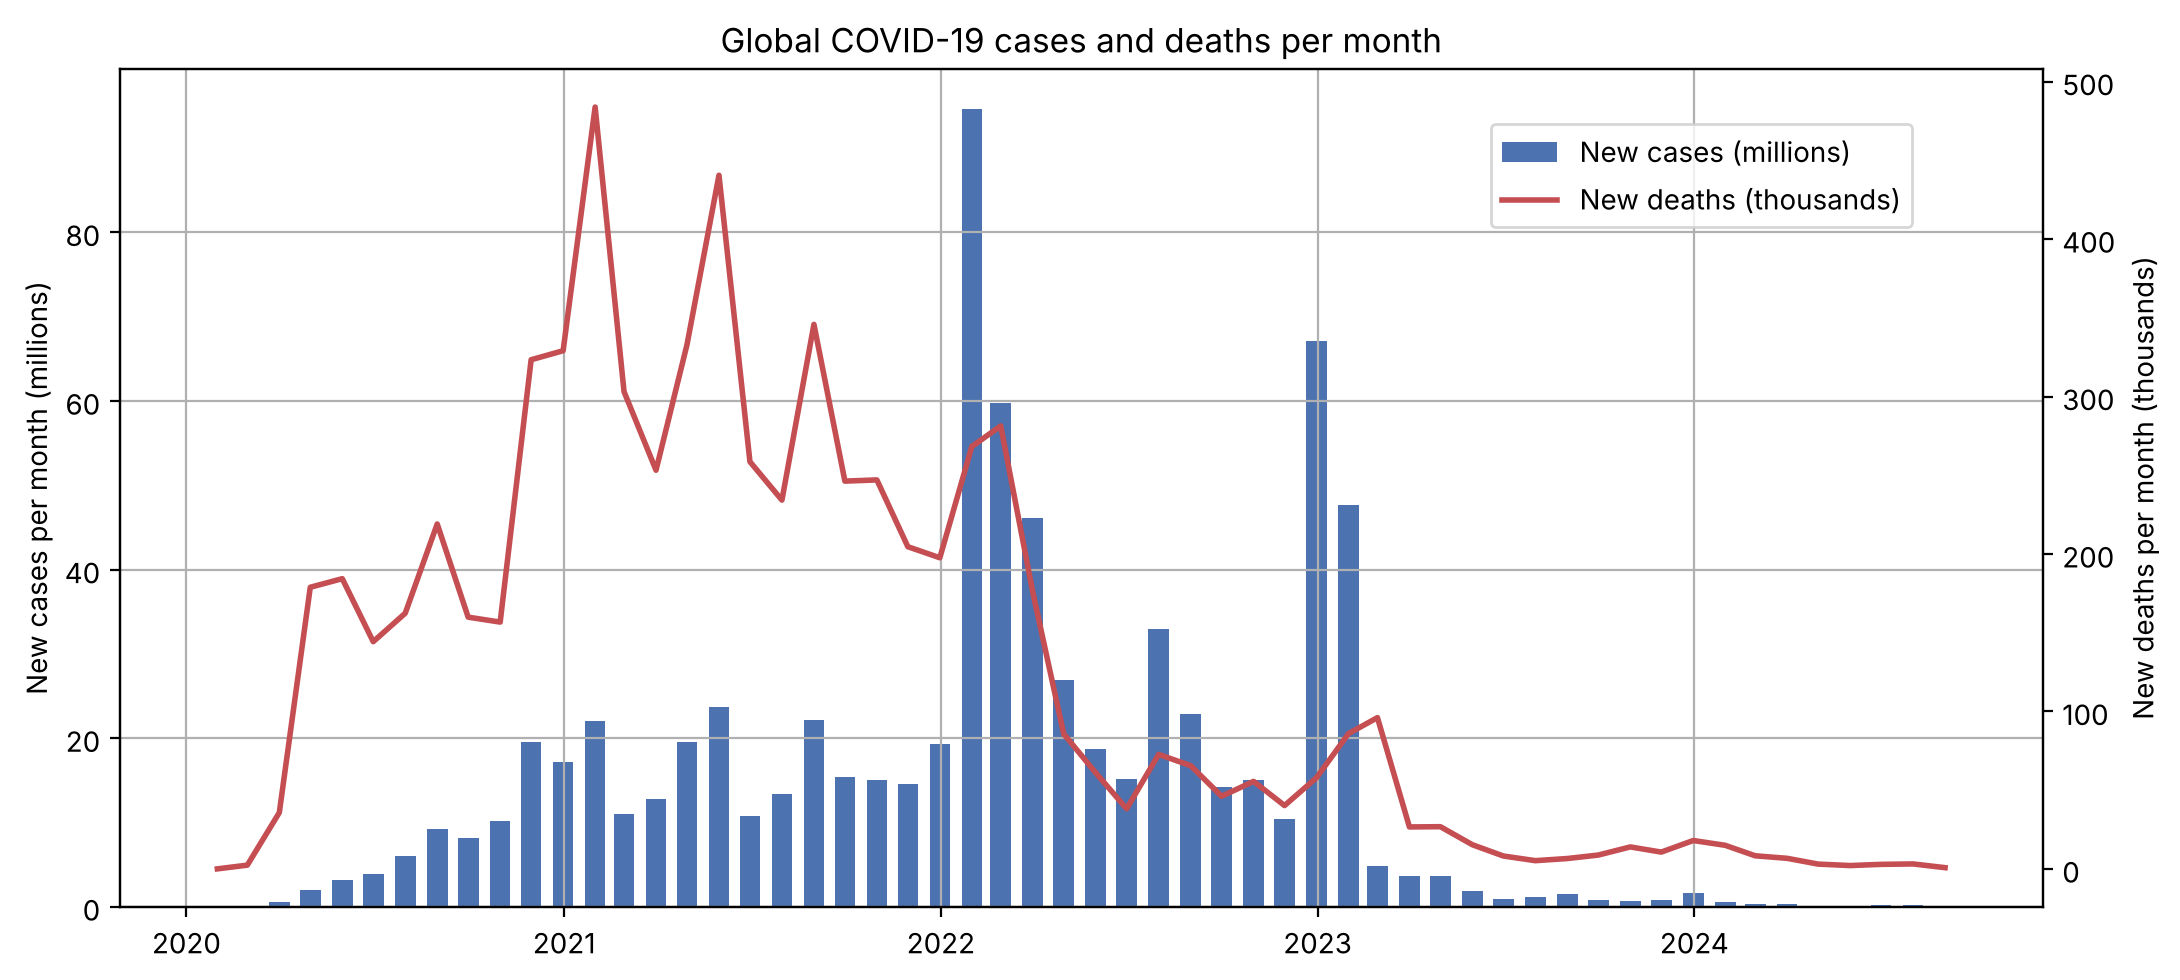

Month with most reported cases : January 2022 (94.7 M)
Month with most reported deaths: January 2021 (484 K)


In [10]:
daily = (countries.groupby("date")[["new_cases", "new_deaths"]]
         .sum()
         .compute()
         .sort_index())
monthly = daily.resample("ME").sum()

fig, ax1 = plt.subplots()
ax1.bar(monthly.index, monthly["new_cases"] / 1e6, width=20, color="#4C72B0", label="New cases (millions)")
ax1.set_ylabel("New cases per month (millions)")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["new_deaths"] / 1e3, color="#C44E52", lw=2, label="New deaths (thousands)")
ax2.set_ylabel("New deaths per month (thousands)")
ax2.grid(False)
ax1.set_title("Global COVID-19 cases and deaths per month")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
plt.tight_layout()
plt.show()

peak_cases = monthly["new_cases"].idxmax()
peak_deaths = monthly["new_deaths"].idxmax()
print("Month with most reported cases :", peak_cases.strftime("%B %Y"), f"({monthly['new_cases'].max()/1e6:.1f} M)")
print("Month with most reported deaths:", peak_deaths.strftime("%B %Y"), f"({monthly['new_deaths'].max()/1e3:.0f} K)")

### 3.2 Yearly totals
The case fatality rate (CFR) is deaths ÷ cases. It shows how the severity of reported cases changed over time.

In [11]:
yearly = countries.groupby("year")[["new_cases", "new_deaths"]].sum().compute().sort_index()
yearly["case_fatality_rate_%"] = (yearly["new_deaths"] / yearly["new_cases"] * 100).round(2)
yearly.astype({"new_cases": "int64", "new_deaths": "int64"})

,new_cases,new_deaths,case_fatality_rate_%
year,,,
2020,80267309,1896289,2.36
2021,200187558,3547675,1.77
2022,423906456,1248924,0.29
2023,69236092,322630,0.47
2024,2063363,42258,2.05


### 3.3 Latest snapshot per country
For each country we take its **maximum** cumulative values. Cumulative counters only increase, so the maximum equals the latest value.

In [12]:
latest = (countries.groupby(["location", "continent"])
          .agg({"total_cases": "max", "total_deaths": "max",
                "total_deaths_per_million": "max", "total_cases_per_million": "max",
                "people_fully_vaccinated_per_hundred": "max", "population": "max",
                "gdp_per_capita": "max", "median_age": "max", "aged_65_older": "max",
                "life_expectancy": "max", "hospital_beds_per_thousand": "max"})
          .compute()
          .reset_index())
print("Countries in snapshot:", len(latest))
latest.sort_values("total_deaths", ascending=False).head(10)[
    ["location", "continent", "total_cases", "total_deaths", "total_deaths_per_million"]]

Countries in snapshot: 237


,location,continent,total_cases,total_deaths,total_deaths_per_million
224,United States,North America,103436829.0,1193165.0,3493.55
28,Brazil,South America,37511921.0,702116.0,3338.54
96,India,Asia,45041748.0,533623.0,374.36
174,Russia,Europe,24268728.0,403188.0,2769.53
134,Mexico,North America,7619458.0,334551.0,2601.22
223,United Kingdom,Europe,24974629.0,232112.0,3404.43
165,Peru,South America,4526977.0,220975.0,6601.11
103,Italy,Europe,26781078.0,197307.0,3309.46
78,Germany,Europe,38437756.0,174979.0,2080.95
72,France,Europe,38997490.0,168091.0,2615.09


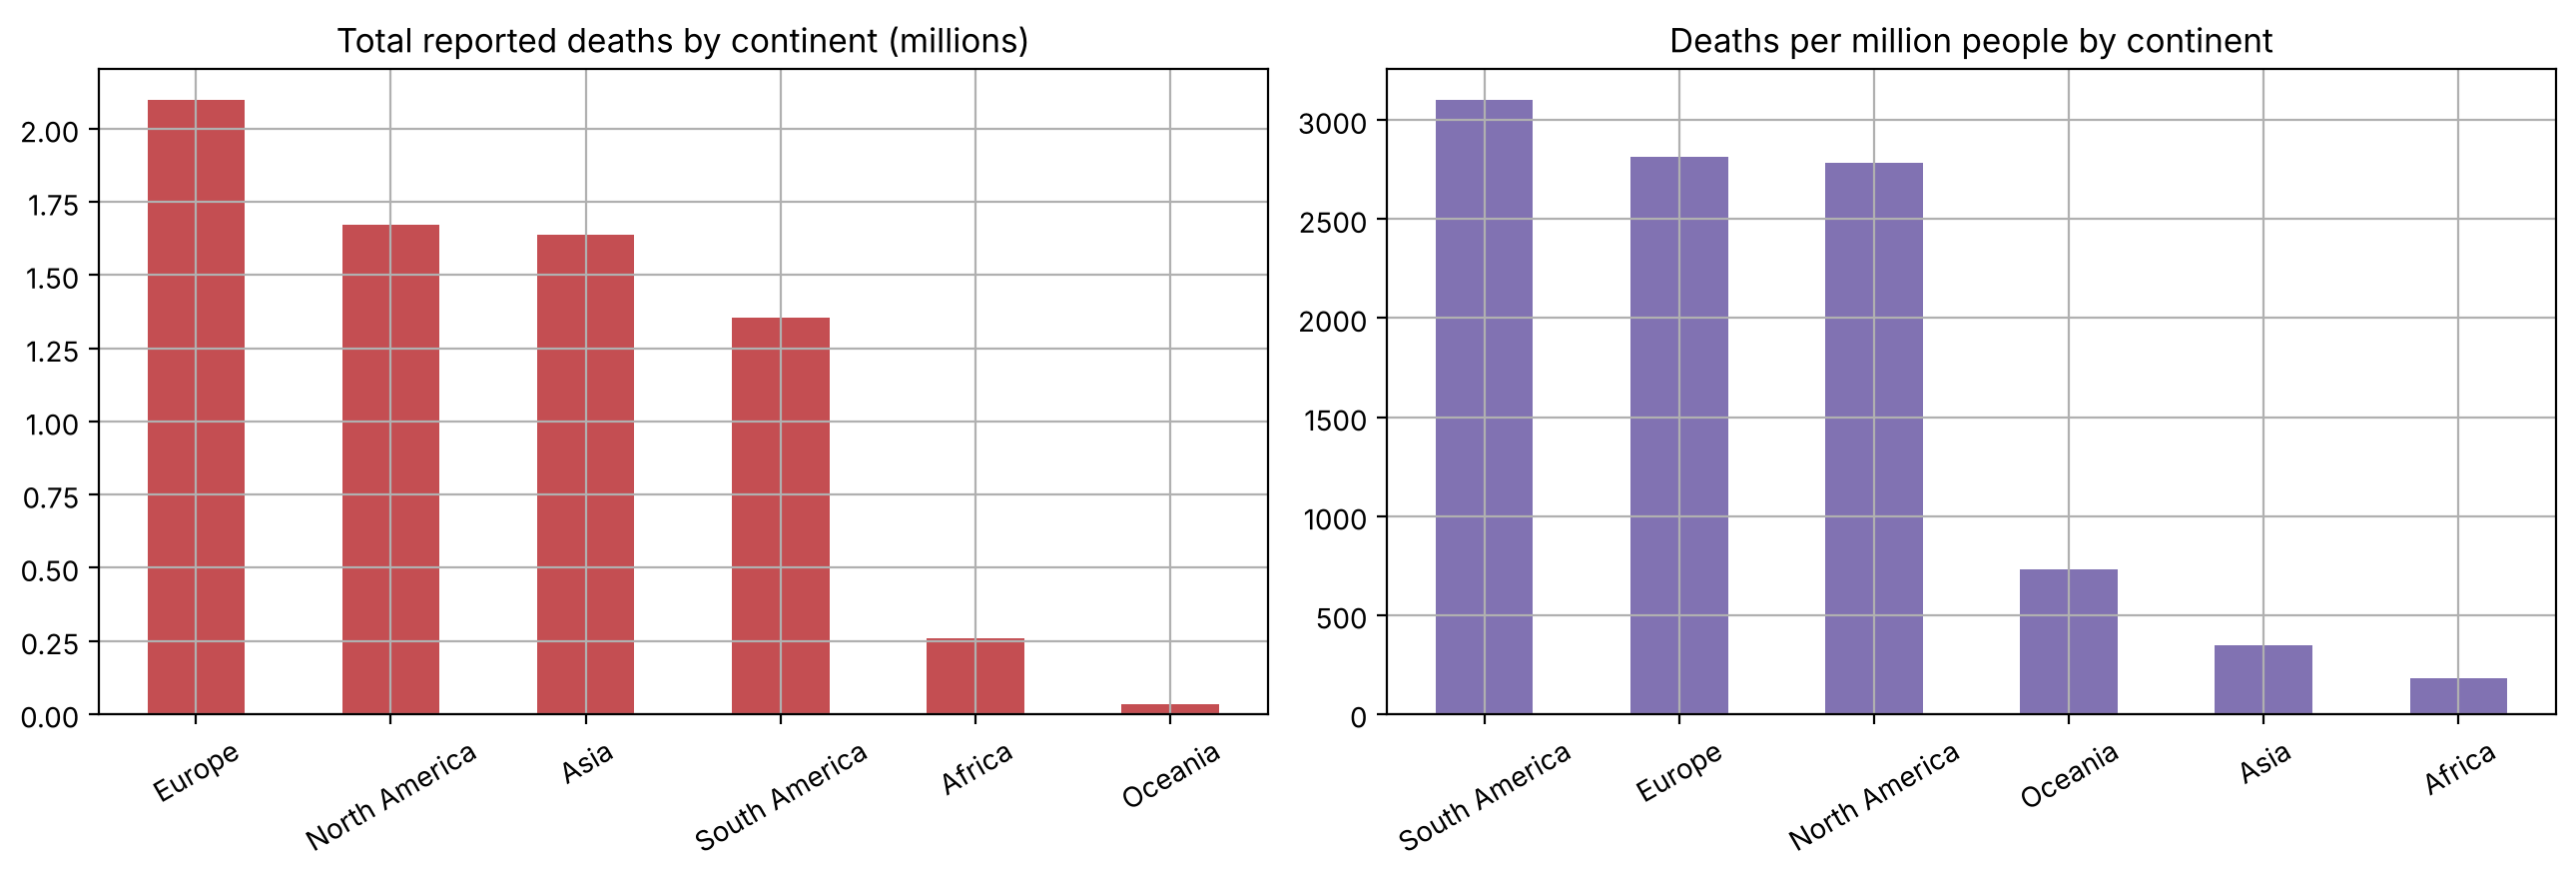

,total_cases,total_deaths,population,deaths_per_million
continent,,,,
Europe,252642589.0,2099271.0,7.456292e+08,2815.0
North America,124492666.0,1671178.0,6.003237e+08,2784.0
Asia,301532347.0,1637249.0,4.721455e+09,347.0
South America,68809418.0,1355939.0,4.368167e+08,3104.0
Africa,13145540.0,259118.0,1.426737e+09,182.0
Oceania,15003352.0,32918.0,4.503891e+07,731.0


In [13]:
# Totals by continent
by_continent = (latest.groupby("continent")[["total_cases", "total_deaths", "population"]]
                .sum()
                .assign(deaths_per_million=lambda d: d.total_deaths / d.population * 1e6)
                .sort_values("total_deaths", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
(by_continent["total_deaths"] / 1e6).plot.bar(ax=axes[0], color="#C44E52")
axes[0].set_title("Total reported deaths by continent (millions)")
axes[0].set_xlabel("")
by_continent["deaths_per_million"].sort_values(ascending=False).plot.bar(ax=axes[1], color="#8172B2")
axes[1].set_title("Deaths per million people by continent")
axes[1].set_xlabel("")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
by_continent.round(0)

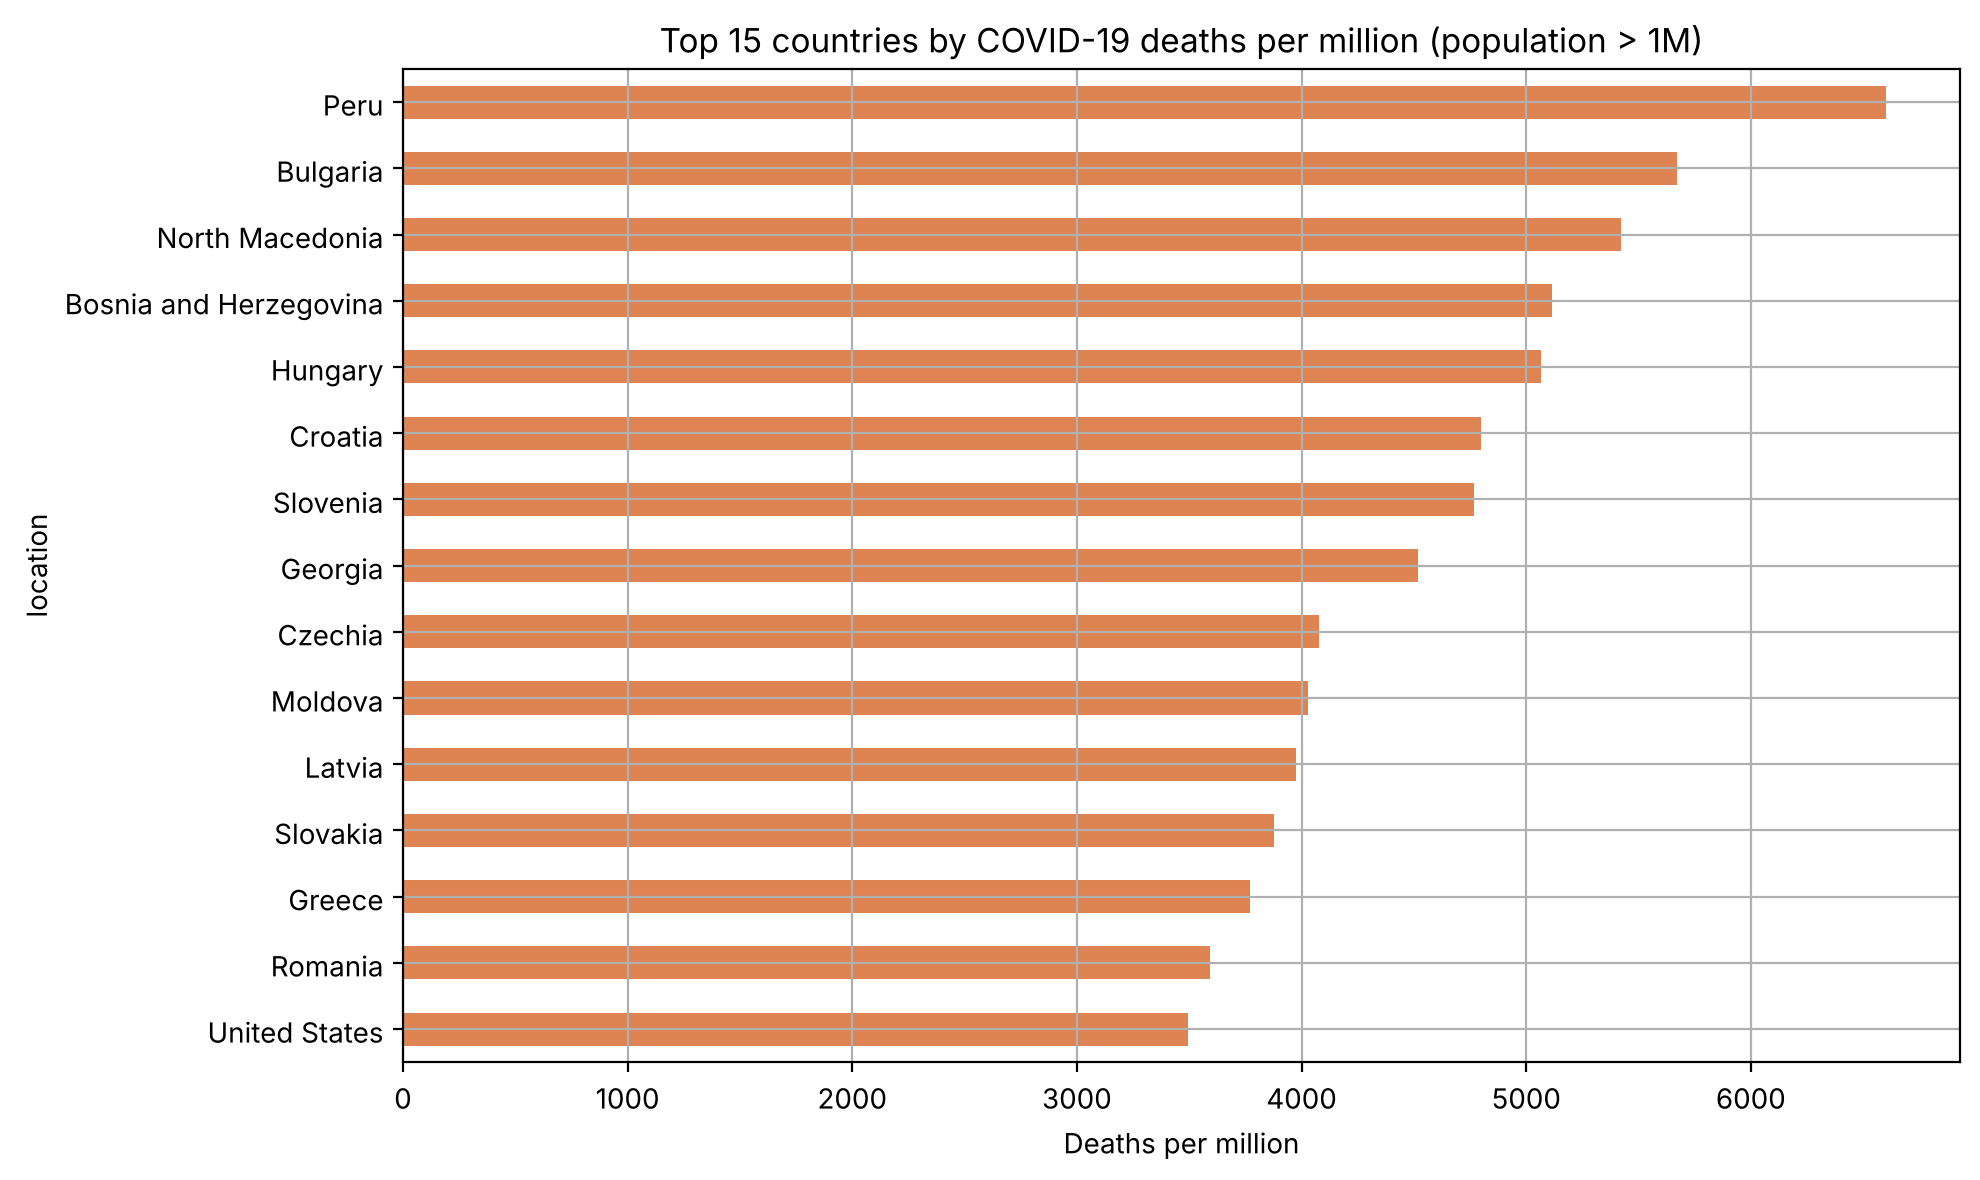

In [14]:
# Top 15 countries by deaths per million (countries with population above 1 million,
# so very small territories don't dominate the ranking)
top_dpm = (latest[latest["population"] > 1e6]
           .nlargest(15, "total_deaths_per_million")
           .set_index("location")["total_deaths_per_million"])
top_dpm.sort_values().plot.barh(color="#DD8452", figsize=(10, 6))
plt.title("Top 15 countries by COVID-19 deaths per million (population > 1M)")
plt.xlabel("Deaths per million")
plt.tight_layout()
plt.show()

### 3.4 What is linked to higher death rates?
Correlation between deaths per million and country-level indicators.

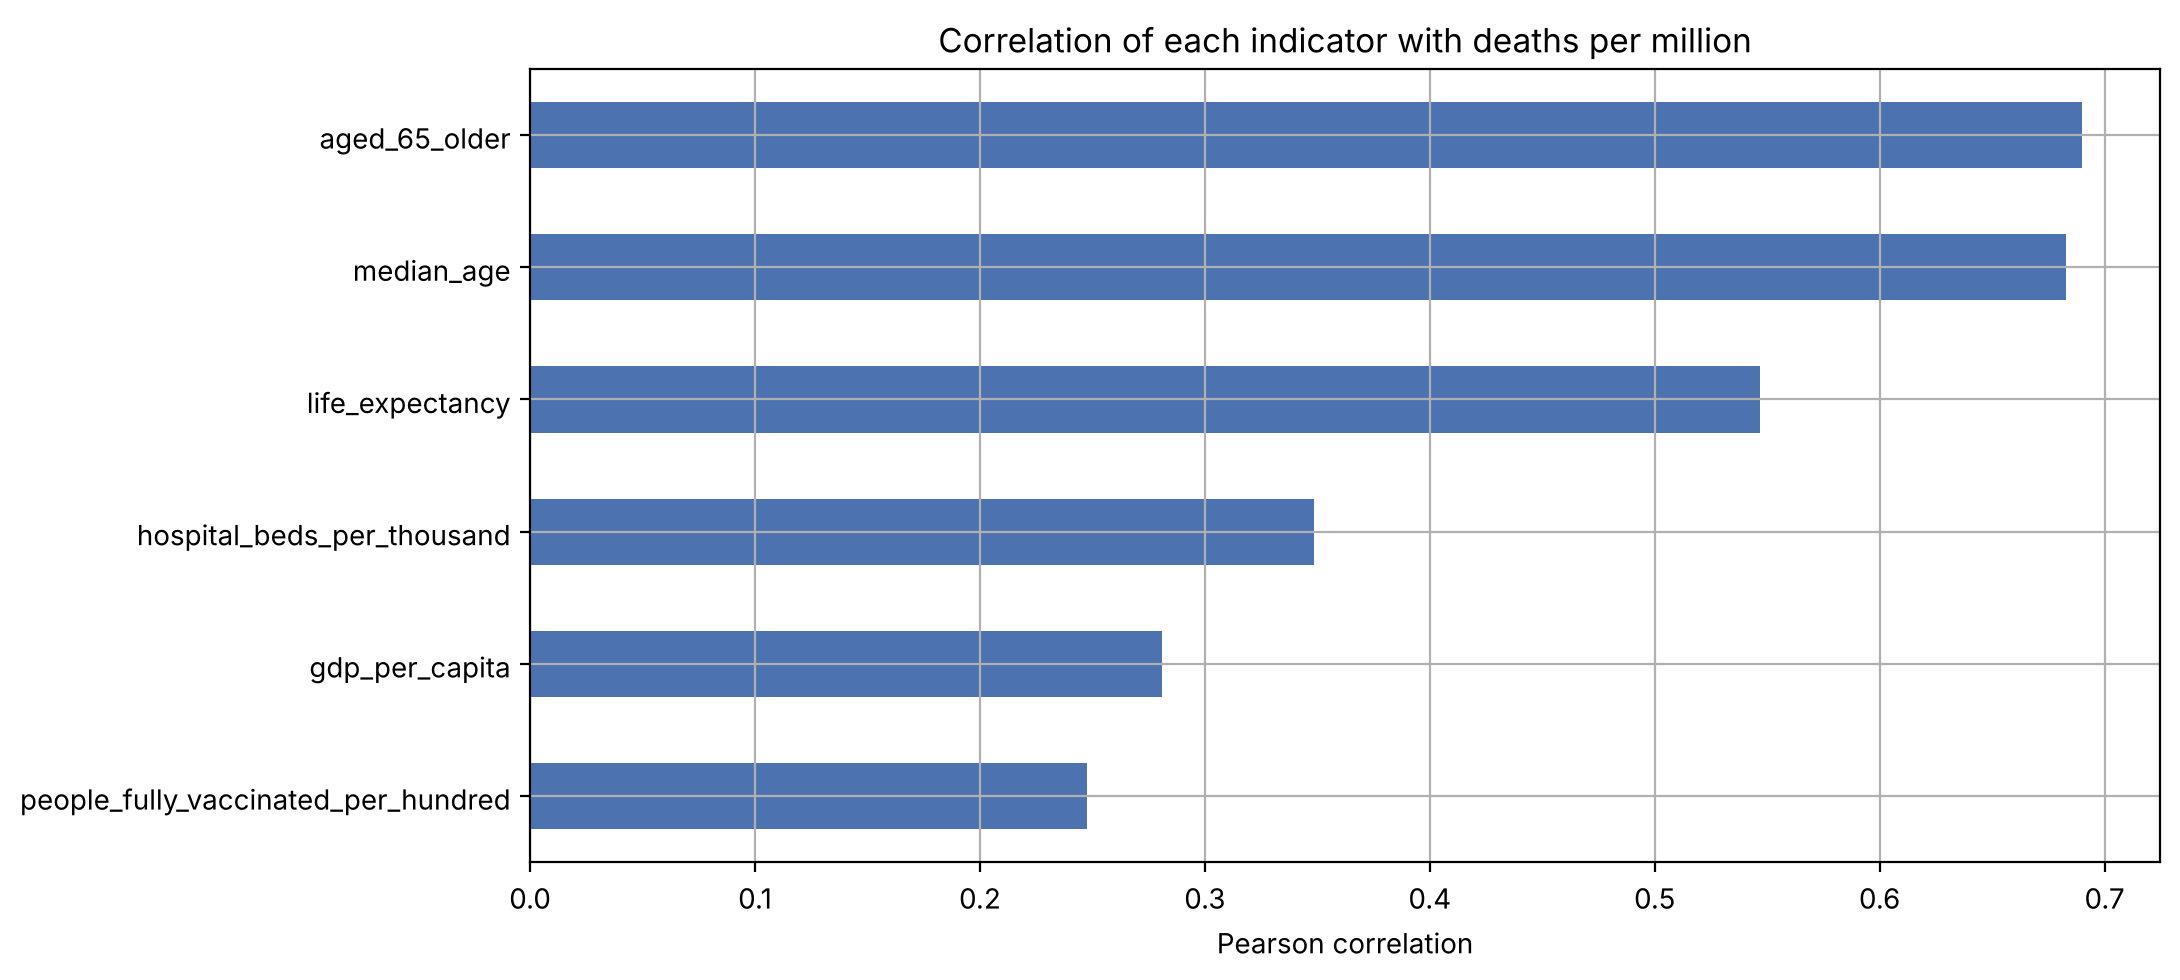

,correlation
people_fully_vaccinated_per_hundred,0.248
gdp_per_capita,0.281
hospital_beds_per_thousand,0.349
life_expectancy,0.547
median_age,0.683
aged_65_older,0.690


In [15]:
indicators = ["median_age", "aged_65_older", "life_expectancy", "gdp_per_capita",
              "hospital_beds_per_thousand", "people_fully_vaccinated_per_hundred"]
corr = (latest[latest["population"] > 1e6][indicators + ["total_deaths_per_million"]]
        .corr()["total_deaths_per_million"]
        .drop("total_deaths_per_million")
        .sort_values())
corr.plot.barh(color=["#C44E52" if v < 0 else "#4C72B0" for v in corr])
plt.title("Correlation of each indicator with deaths per million")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()
corr.round(3).to_frame("correlation")

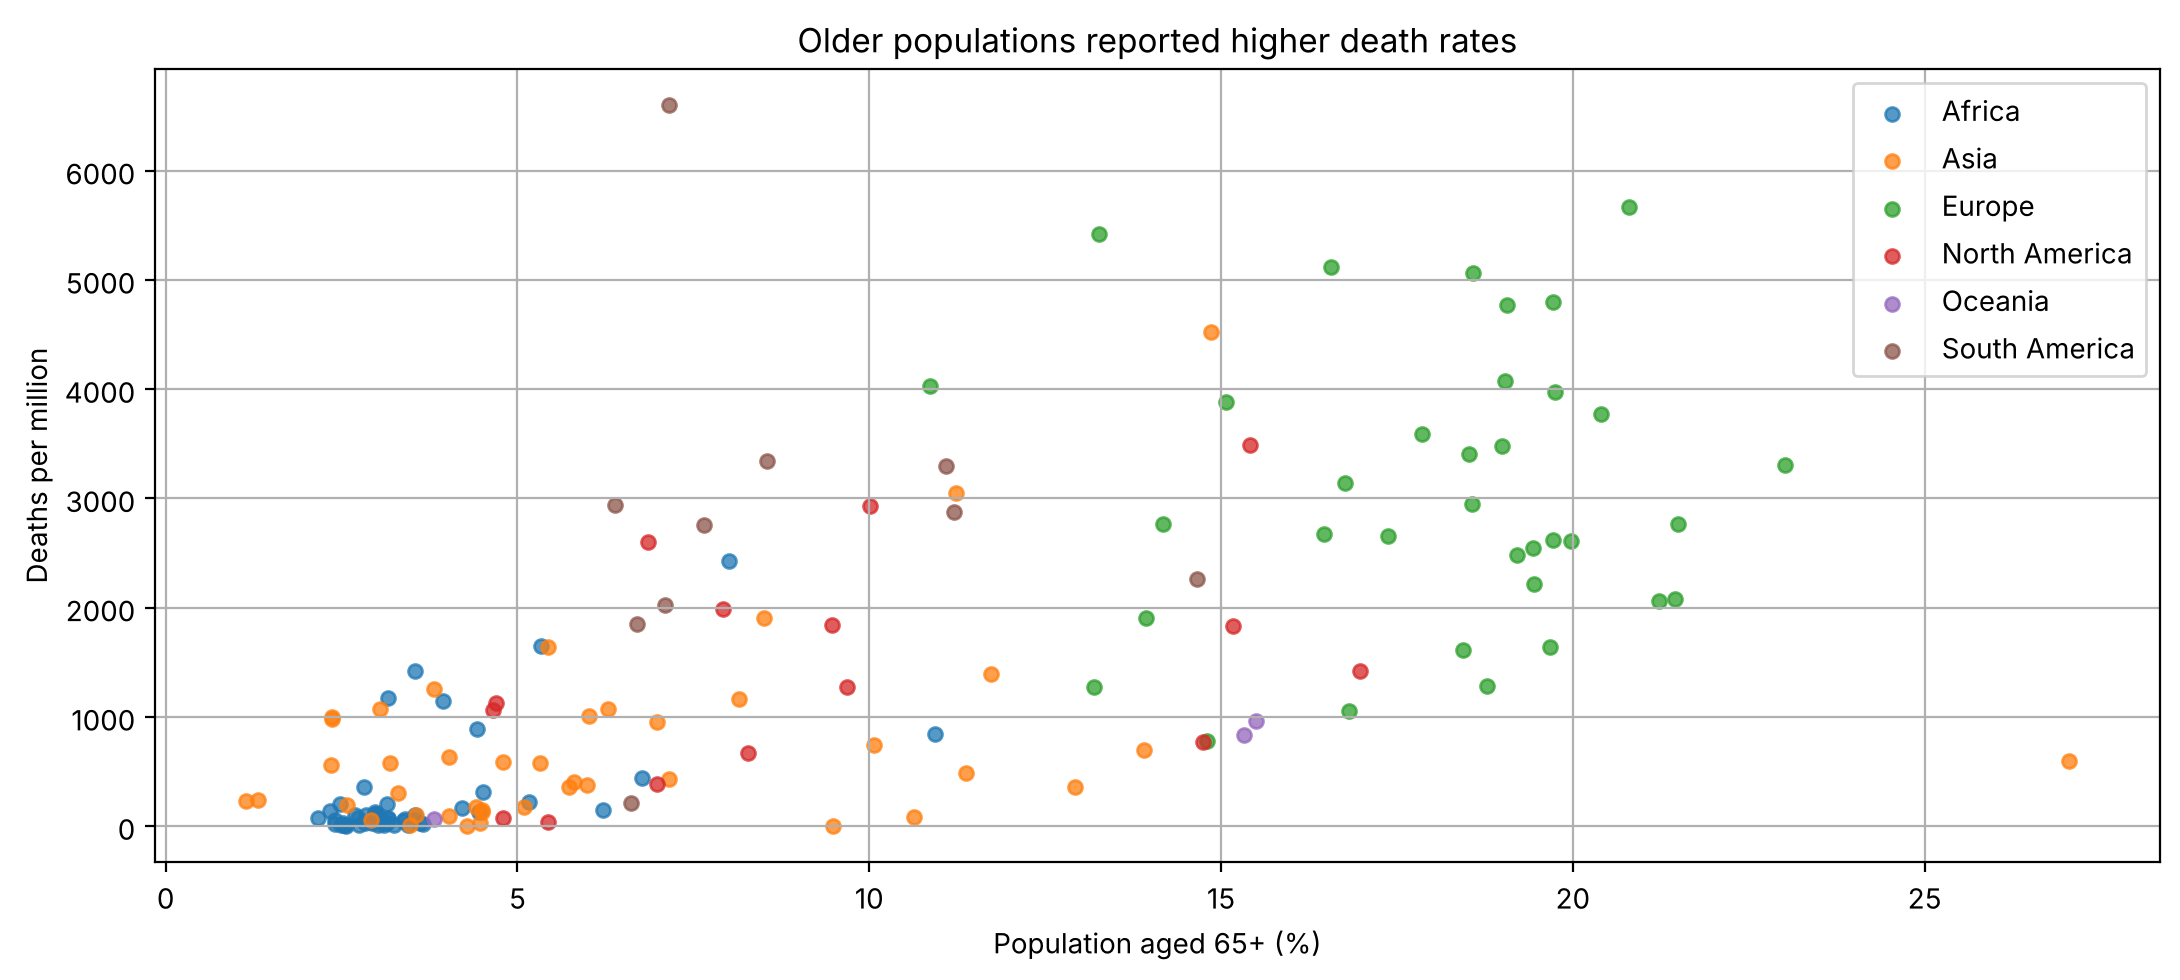

In [16]:
# Scatter: share of people aged 65+ vs deaths per million
sub = latest[latest["population"] > 1e6].dropna(subset=["aged_65_older", "total_deaths_per_million"])
colors = {c: plt.cm.tab10(i) for i, c in enumerate(sorted(sub["continent"].unique()))}
for cont, g in sub.groupby("continent"):
    plt.scatter(g["aged_65_older"], g["total_deaths_per_million"], s=25, alpha=0.75,
                color=colors[cont], label=cont)
plt.xlabel("Population aged 65+ (%)")
plt.ylabel("Deaths per million")
plt.title("Older populations reported higher death rates")
plt.legend()
plt.tight_layout()
plt.show()

> **Caution:** these are correlations, not causes. Older and richer countries also tend to **test and record deaths more completely**, which raises their reported numbers.

## 4. Scalability demonstration

Three experiments show how Dask scales:
1. **Storage format:** CSV vs columnar **Parquet**
2. **Data size:** the same query on 1×, 2×, 4× and 8× the data
3. **Parallelism:** the same query with 1 thread vs all available cores

In [17]:
# A reusable "heavy" query: monthly cases and deaths per continent
def heavy_query(frame):
    f = frame[~frame["iso_code"].str.startswith("OWID_")]
    f = f.assign(month=f["date"].str.slice(0, 7))
    return f.groupby(["continent", "month"])[["new_cases", "new_deaths"]].sum()

def timed(fn, repeats=2):
    """Run fn() several times and return the best wall-clock time in seconds."""
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t0)
    return best

### 4.1 CSV vs Parquet
Parquet stores data **by column** and compresses it. When a query needs only a few columns, Dask reads only those columns from disk.

In [18]:
PARQUET_PATH = os.path.join(DATA_DIR, "owid_parquet")
if not os.path.exists(PARQUET_PATH):
    ddf.to_parquet(PARQUET_PATH, write_index=False)

parquet_size = sum(os.path.getsize(os.path.join(PARQUET_PATH, f)) for f in os.listdir(PARQUET_PATH)) / 1e6
csv_size = os.path.getsize(CSV_PATH) / 1e6

needed = ["iso_code", "continent", "date", "new_cases", "new_deaths"]
t_csv = timed(lambda: heavy_query(dd.read_csv(CSV_PATH, blocksize="16MB", dtype=text_cols,
                                              assume_missing=True, usecols=needed)).compute())
t_parquet = timed(lambda: heavy_query(dd.read_parquet(PARQUET_PATH, columns=needed)).compute())

fmt = pd.DataFrame({"size_MB": [csv_size, parquet_size], "query_seconds": [t_csv, t_parquet]},
                   index=["CSV", "Parquet"]).round(2)
print(f"Parquet is {csv_size/parquet_size:.1f}x smaller and the query is {t_csv/t_parquet:.1f}x faster.")
fmt

Parquet is 7.2x smaller and the query is 4.2x faster.


,size_MB,query_seconds
CSV,98.39,0.48
Parquet,13.74,0.11


### 4.2 Scaling with data size
We stack the dataset on itself to make inputs **2×, 4× and 8× larger** (up to about 3.4 million rows) and time the same query. If the approach scales, time should grow roughly in line with the data, without running out of memory.

In [19]:
base = dd.read_parquet(PARQUET_PATH, columns=needed)
results = []
for k in [1, 2, 4, 8]:
    big = dd.concat([base] * k)                  # k copies -> k times the rows
    rows = len(big)
    secs = timed(lambda: heavy_query(big).compute())
    results.append({"multiplier": k, "rows": rows, "partitions": big.npartitions,
                    "seconds": round(secs, 2), "rows_per_second": int(rows / secs)})
scale = pd.DataFrame(results)
scale

,multiplier,rows,partitions,seconds,rows_per_second
0,1,429435,6,0.09,4718659
1,2,858870,12,0.14,6314925
2,4,1717740,24,0.18,9659553
3,8,3435480,48,0.40,8603623


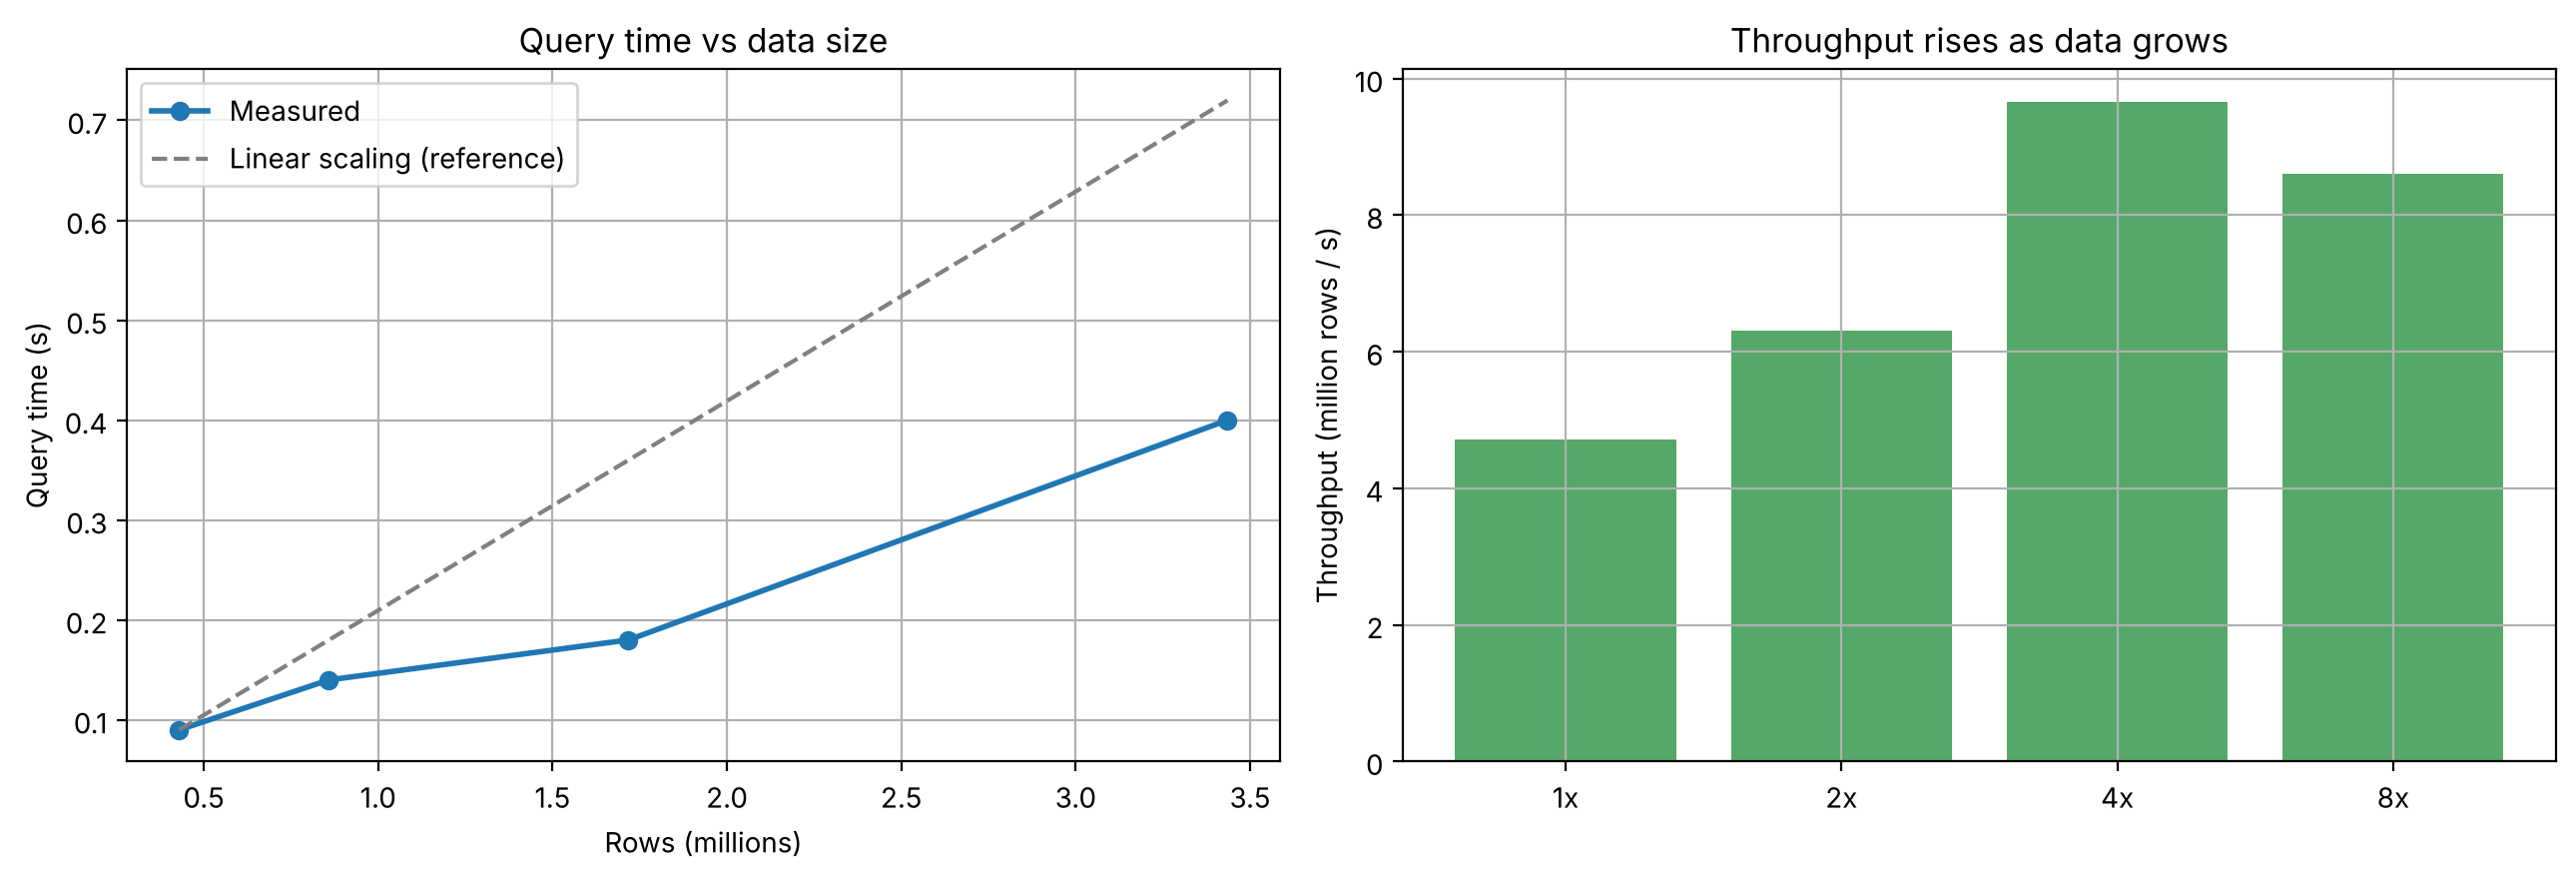

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(scale["rows"] / 1e6, scale["seconds"], "o-", lw=2, label="Measured")
ideal = scale["seconds"].iloc[0] * scale["multiplier"]
axes[0].plot(scale["rows"] / 1e6, ideal, "--", color="grey", label="Linear scaling (reference)")
axes[0].set_xlabel("Rows (millions)")
axes[0].set_ylabel("Query time (s)")
axes[0].set_title("Query time vs data size")
axes[0].legend()
axes[1].bar(scale["multiplier"].astype(str) + "x", scale["rows_per_second"] / 1e6, color="#55A868")
axes[1].set_ylabel("Throughput (million rows / s)")
axes[1].set_title("Throughput rises as data grows")
plt.tight_layout()
plt.show()

### 4.3 Parallelism: 1 thread vs all cores
Dask's threaded scheduler processes partitions at the same time. We run the 8× query with 1 worker and then with every available core.

In [21]:
big8 = dd.concat([base] * 8)
par = []
for workers in sorted({1, os.cpu_count()}):
    secs = timed(lambda: heavy_query(big8).compute(scheduler="threads", num_workers=workers))
    par.append({"workers": workers, "seconds": round(secs, 2)})
par = pd.DataFrame(par)
par["speed_up"] = (par["seconds"].iloc[0] / par["seconds"]).round(2)
par

,workers,seconds,speed_up
0,1,0.63,1.0
1,2,0.42,1.5


On a machine with more cores (or a Dask cluster with `dask.distributed`), the same code spreads across more workers **with no changes**. That is the main scalability benefit of Dask.

## 5. Summary of insights

**Big-data processing**
- Dask processed about **429,000 rows × 67 columns** in parallel partitions, and the scaling test went up to **~3.4 million rows**, without loading everything into memory at once.
- Converting CSV to **Parquet** made the data several times smaller and the queries several times faster. Columnar storage is the first optimisation to make for big data.
- Making the data **8× larger (3.4 million rows) made the query only about 4–5× slower**. Throughput (rows per second) actually *rose* as the data grew, because fixed start-up costs are spread over more rows. The pipeline scales predictably, better than linear.
- Using all CPU cores instead of one made the query noticeably faster. On a bigger machine or a Dask cluster the same code would speed up further.

**COVID-19 findings**
- Reported cases peaked at the start of **2022** (the Omicron wave), while the deadliest months came earlier, during **late 2020 – early 2021**.
- The **case fatality rate fell sharply**, from about 2.4% in 2020 to about 0.3% in 2022. Vaccination, better treatment, wider testing (which catches milder cases), and the less severe Omicron variant all contributed. The apparent rise in 2024 reflects how few cases were still being reported, not a deadlier virus.
- **South America, Europe and North America** have the highest deaths per million, while Africa and Asia report far lower rates. **Peru** has the highest rate of any country with over 1 million people, followed by a group of **Central and Eastern European** countries (Bulgaria, North Macedonia, Bosnia and Herzegovina, Hungary and others).
- The **United States** has the most reported deaths in absolute numbers (about 1.19 million), followed by Brazil and India.
- Deaths per million are **positively correlated with an older population** (median age, % aged 65+) and with life expectancy. This shows how strongly age drives COVID-19 mortality. Vaccination rate is *also* slightly positive. This does not mean vaccines raised deaths: richer, older countries both vaccinated more and recorded deaths more completely. It is a reminder that correlation is not causation.

*Exact figures for each point are in the outputs above.*